# Uçtan Uca Yapay Zeka Projesi: İkinci El Araç Fiyat Tahmini
**Yapay Zeka İçin Basitleştirilmiş Python — Proje Envanteri**
Muhammed Mirhan Serim · Software Persona Yapay Zeka Mesleki Gelişim Programı, 30. Dönem

Bu not defteri, gerçek bir ikinci el araç veri setinden yola çıkarak aracın satış fiyatını tahmin eden bir yapay zeka uygulamasını
uçtan uca geliştirir: **problem tanımı → veri hazırlama → keşif ve görselleştirme → model → değerlendirme → mini uygulama.**

Araçlar: Python, Google Colab, Pandas, NumPy, Matplotlib, scikit-learn

## Aşama 1 · Problem Tanımı ve Proje Planı

| | |
|---|---|
| **Problem cümlesi** | Bir aracın *model yılı, kilometresi, sıfır fiyatı, yakıt tipi, vites türü, satıcı türü ve önceki sahip sayısı* bilgilerinden **ikinci el satış fiyatını** tahmin et. |
| **Hedef değişken (y)** | `Selling_Price`: aracın ikinci el satış fiyatı (lakh ₹, 1 lakh = 100.000 Hint rupisi) |
| **Problem türü** | Çıktı sürekli bir sayı olduğu için **regresyon** |

**Neden önemli?** İkinci el araç alım-satımında fiyat çoğu zaman tahmine ve pazarlığa dayanır. Satıcı aracını
değerinin altında satabilir, alıcı da fazla ödeyebilir. Aracın temel özelliklerinden adil bir fiyat aralığı öneren
basit bir model hem bireysel kullanıcılara hem de galerilere hızlı ve tutarlı bir başlangıç fiyatı sunar.
Ayrıca hangi özelliğin fiyatı ne kadar etkilediğini görmek, kullanıcıların daha bilinçli karar vermesini sağlar.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
RASTGELE = 42  # tekrarlanabilir sonuçlar için sabit tohum

## Aşama 2 · Veri Toplama ve Hazırlama

**Veri kaynağı:** *Vehicle Dataset from CarDekho* (Kaggle, N. Birla). Hindistan'daki CarDekho platformunda listelenmiş
301 ikinci el araç ilanı. Not defteri Colab'da da çalışsın diye veri, dosya yanımızda yoksa GitHub deposundan indirilir.

In [2]:
import os
VERI_URL = "https://raw.githubusercontent.com/mirhanserim/yapay-zeka-portfolyo/main/1_Python_Arac_Fiyat/arac_verisi.csv"
kaynak = "arac_verisi.csv" if os.path.exists("arac_verisi.csv") else VERI_URL
df = pd.read_csv(kaynak)
print("Boyut:", df.shape)
df.head()

Boyut: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


### Veri sözlüğü

| Sütun | Tip | Anlamı | Rol |
|---|---|---|---|
| `Car_Name` | kategorik | Araç model adı | kullanılmadı (98 farklı değer, çok seyrek) |
| `Year` | sayısal | Model yılı | özellik (yaşa çevrilir) |
| `Selling_Price` | sayısal | İkinci el satış fiyatı (lakh ₹) | **hedef (y)** |
| `Present_Price` | sayısal | Aracın sıfır fiyatı (lakh ₹) | özellik |
| `Kms_Driven` | sayısal | Toplam kilometre | özellik |
| `Fuel_Type` | kategorik | Petrol / Diesel / CNG | özellik |
| `Seller_Type` | kategorik | Dealer (galeri) / Individual (bireysel) | özellik |
| `Transmission` | kategorik | Manual / Automatic | özellik |
| `Owner` | sayısal | Önceki sahip sayısı | özellik |

In [3]:
print("Sütun tipleri:\n", df.dtypes, sep="")
print("\nEksik değer sayısı:", int(df.isnull().sum().sum()))
print("Tekrarlanan satır sayısı:", int(df.duplicated().sum()))

Sütun tipleri:
Car_Name             str
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type            str
Seller_Type          str
Transmission         str
Owner              int64
dtype: object

Eksik değer sayısı: 0
Tekrarlanan satır sayısı: 2


### Temizleme adımları
1. **Eksik değer:** `isnull()` kontrolünde eksik değer bulunmadı, `fillna`/`dropna` gerekmedi.
2. **Tekrarlanan satırlar:** Aynı ilan iki kez girilmiş 2 satır `drop_duplicates()` ile çıkarıldı.
3. **Aykırı değer:** 500.000 km'lik tek bir kayıt fiziksel olarak mümkün ama dağılımın çok dışında. Modeli tek bir ilan bozmasın diye çıkarıldı.
4. **Özellik türetme:** `Year` yerine daha anlamlı olan **`Arac_Yasi`** (veri setindeki en yeni yıla göre) hesaplandı.
5. **Kategorik → sayısal:** Yakıt, satıcı ve vites sütunları `get_dummies` ile 0/1 sütunlarına çevrildi.

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
df = df[df["Kms_Driven"] < 400_000].reset_index(drop=True)
REFERANS_YIL = df["Year"].max() + 1
df["Arac_Yasi"] = REFERANS_YIL - df["Year"]
print("Temizlik sonrası boyut:", df.shape, "| referans yıl:", REFERANS_YIL)

Temizlik sonrası boyut: (298, 10) | referans yıl: 2019


## Aşama 3 · Keşifçi Veri Analizi (EDA) ve Görselleştirme

In [5]:
df[["Selling_Price", "Present_Price", "Kms_Driven", "Arac_Yasi", "Owner"]].describe().round(2)

,Selling_Price,Present_Price,Kms_Driven,Arac_Yasi,Owner
count,298.00,298.00,298.00,298.00,298.00
mean,4.60,7.56,35362.78,5.37,0.04
std,4.99,8.57,28334.52,2.88,0.25
min,0.10,0.32,500.00,1.00,0.00
25%,0.90,1.21,15000.00,3.00,0.00
50%,3.56,6.25,31802.00,5.00,0.00
75%,6.00,9.84,48575.25,7.00,0.00
max,35.00,92.60,213000.00,16.00,3.00


In [6]:
print("Kategorik sütunların dağılımı (value_counts):")
for sutun in ["Fuel_Type", "Seller_Type", "Transmission", "Owner"]:
    print(f"\n{sutun}:", df[sutun].value_counts().to_dict())

Kategorik sütunların dağılımı (value_counts):

Fuel_Type: {'Petrol': 238, 'Diesel': 58, 'CNG': 2}

Seller_Type: {'Dealer': 193, 'Individual': 105}

Transmission: {'Manual': 260, 'Automatic': 38}

Owner: {0: 287, 1: 10, 3: 1}


In [7]:
print("Yakıt tipine göre ortalama satış fiyatı (lakh ₹):")
print(df.groupby("Fuel_Type")["Selling_Price"].agg(["count", "mean"]).round(2))
print("\nVites türüne göre:")
print(df.groupby("Transmission")["Selling_Price"].agg(["count", "mean"]).round(2))
print("\nSatıcı türüne göre:")
print(df.groupby("Seller_Type")["Selling_Price"].agg(["count", "mean"]).round(2))

Yakıt tipine göre ortalama satış fiyatı (lakh ₹):
           count   mean
Fuel_Type              
CNG            2   3.10
Diesel        58  10.10
Petrol       238   3.28

Vites türüne göre:
              count  mean
Transmission             
Automatic        38  9.31
Manual          260  3.92

Satıcı türüne göre:
             count  mean
Seller_Type             
Dealer         193  6.63
Individual     105  0.88


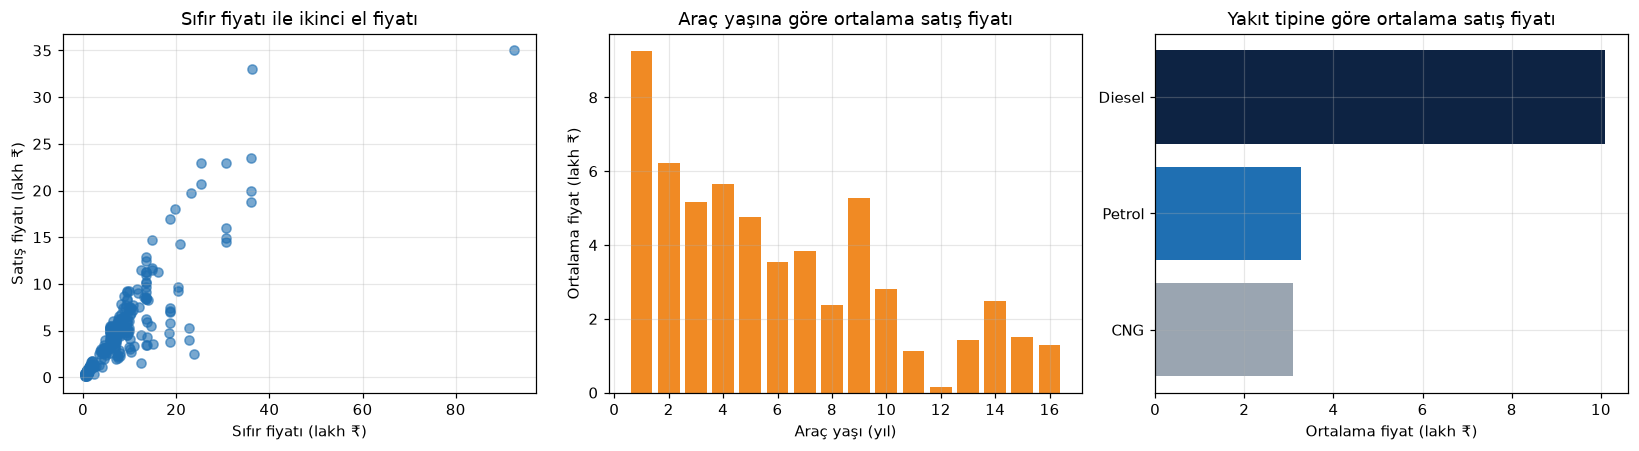

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].scatter(df["Present_Price"], df["Selling_Price"], alpha=0.6, c="#1f6fb2")
ax[0].set_title("Sıfır fiyatı ile ikinci el fiyatı")
ax[0].set_xlabel("Sıfır fiyatı (lakh ₹)"); ax[0].set_ylabel("Satış fiyatı (lakh ₹)")

ort = df.groupby("Arac_Yasi")["Selling_Price"].mean()
ax[1].bar(ort.index, ort.values, color="#f08a24")
ax[1].set_title("Araç yaşına göre ortalama satış fiyatı")
ax[1].set_xlabel("Araç yaşı (yıl)"); ax[1].set_ylabel("Ortalama fiyat (lakh ₹)")

yakit = df.groupby("Fuel_Type")["Selling_Price"].mean().sort_values()
ax[2].barh(yakit.index, yakit.values, color=["#9aa5b1", "#1f6fb2", "#0d2343"])
ax[2].set_title("Yakıt tipine göre ortalama satış fiyatı")
ax[2].set_xlabel("Ortalama fiyat (lakh ₹)")
plt.tight_layout(); plt.savefig("grafik_eda.png", dpi=160, bbox_inches="tight"); plt.show()

In [9]:
korelasyon = df[["Selling_Price", "Present_Price", "Kms_Driven", "Arac_Yasi", "Owner"]].corr()["Selling_Price"].drop("Selling_Price")
print("Satış fiyatı ile korelasyon:\n", korelasyon.sort_values(ascending=False).round(2), sep="")

Satış fiyatı ile korelasyon:
Present_Price    0.88
Kms_Driven       0.09
Owner           -0.09
Arac_Yasi       -0.23
Name: Selling_Price, dtype: float64


### Keşif Bulguları
1. **Sıfır fiyatı en belirleyici özellik:** `Present_Price` ile satış fiyatı arasında çok güçlü doğrusal bir ilişki var (korelasyon ≈ 0,88).
2. **Araç yaşlandıkça fiyat düşüyor:** Yaşın fiyatla korelasyonu negatif (≈ −0,23). Tek başına zayıf görünse de sıfır fiyatı sabit tutulduğunda etkisi netleşiyor (modelde her yıl ≈ 0,28 lakh ₹ düşüş).
3. **Dizel araçlar daha pahalı:** Dizel araçların ortalama fiyatı benzinlilerin yaklaşık 3 katı. Bu fark büyük ölçüde dizellerin daha üst segment olmasından kaynaklanıyor.
4. **Otomatik vites ve galeri satışı fiyatı artırıyor:** Bireysel satıcıların araçları çoğunlukla düşük fiyatlı küçük araçlar ve motosikletler.
5. **Kilometrenin etkisi tek başına zayıf:** Km'nin fiyatla korelasyonu yalnızca ≈ 0,09. Km büyük ölçüde yaşla birlikte değiştiği için ayrı bir bilgi taşımıyor.

## Aşama 4 · Model Kurma ve Eğitme

In [10]:
OZELLIKLER = ["Present_Price", "Kms_Driven", "Arac_Yasi", "Owner", "Fuel_Type", "Seller_Type", "Transmission"]
X = pd.get_dummies(df[OZELLIKLER], columns=["Fuel_Type", "Seller_Type", "Transmission"], drop_first=True, dtype=int)
y = df["Selling_Price"]

X_egitim, X_test, y_egitim, y_test = train_test_split(X, y, test_size=0.2, random_state=RASTGELE)
print("Eğitim:", X_egitim.shape, "| Test:", X_test.shape)
print("Kullanılan sütunlar:", list(X.columns))

Eğitim: (238, 8) | Test: (60, 8)
Kullanılan sütunlar: ['Present_Price', 'Kms_Driven', 'Arac_Yasi', 'Owner', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Seller_Type_Individual', 'Transmission_Manual']


In [11]:
model = LinearRegression()
model.fit(X_egitim, y_egitim)

# Karşılaştırma için ikinci bir model: karar ağacı (derinlik sınırlı, aşırı öğrenmeyi azaltmak için)
agac = DecisionTreeRegressor(max_depth=5, random_state=RASTGELE)
agac.fit(X_egitim, y_egitim)

katsayilar = pd.Series(model.coef_, index=X.columns).round(3)
print("Doğrusal regresyon katsayıları:\n", katsayilar, sep="")

Doğrusal regresyon katsayıları:
Present_Price             0.440
Kms_Driven               -0.000
Arac_Yasi                -0.282
Owner                     0.477
Fuel_Type_Diesel          2.274
Fuel_Type_Petrol          0.669
Seller_Type_Individual   -1.352
Transmission_Manual      -1.558
dtype: float64


**Model seçim gerekçesi:** Keşif aşamasında satış fiyatının sıfır fiyatıyla doğrusal bir ilişki gösterdiği görüldü.
Bu yüzden ana model olarak hem yorumlanabilir hem de hızlı olan **Doğrusal Regresyon (LinearRegression)** seçildi.
Katsayıları her özelliğin fiyata etkisini doğrudan gösteriyor. Doğrusal olmayan ilişkileri yakalayıp yakalayamadığını
görmek için **derinliği 5 ile sınırlı bir Karar Ağacı** da karşılaştırma modeli olarak eğitildi.

## Aşama 5 · Tahmin ve Değerlendirme

In [12]:
sonuc = []
for ad, m in [("Doğrusal Regresyon", model), ("Karar Ağacı (derinlik 5)", agac)]:
    tahmin = m.predict(X_test)
    sonuc.append({"Model": ad,
                  "Eğitim R²": round(m.score(X_egitim, y_egitim), 3),
                  "Test R²": round(r2_score(y_test, tahmin), 3),
                  "Test MAE (lakh ₹)": round(mean_absolute_error(y_test, tahmin), 2)})
sonuc = pd.DataFrame(sonuc); sonuc

,Model,Eğitim R²,Test R²,Test MAE (lakh ₹)
0,Doğrusal Regresyon,0.906,0.785,1.38
1,Karar Ağacı (derinlik 5),0.976,0.805,1.29


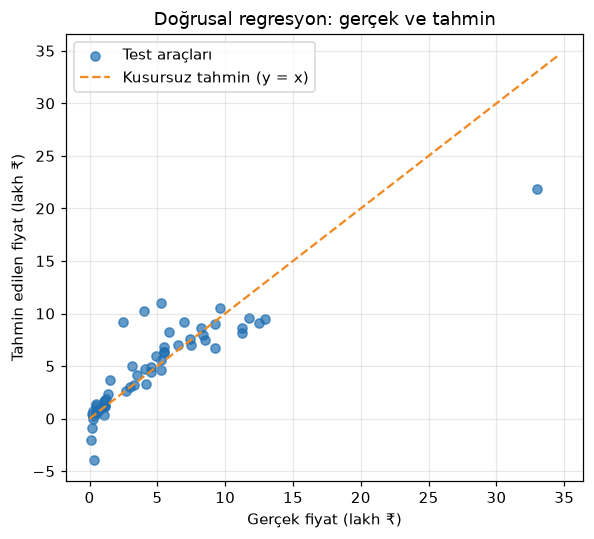

In [13]:
tahmin_lr = model.predict(X_test)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_test, tahmin_lr, alpha=0.7, c="#1f6fb2", label="Test araçları")
sinir = [0, max(y_test.max(), tahmin_lr.max()) * 1.05]
ax.plot(sinir, sinir, "--", c="#f08a24", label="Kusursuz tahmin (y = x)")
ax.set_xlabel("Gerçek fiyat (lakh ₹)"); ax.set_ylabel("Tahmin edilen fiyat (lakh ₹)")
ax.set_title("Doğrusal regresyon: gerçek ve tahmin"); ax.legend()
plt.tight_layout(); plt.savefig("grafik_tahmin.png", dpi=160, bbox_inches="tight"); plt.show()

In [14]:
yeni_araclar = pd.DataFrame([
    {"Present_Price": 6.0,  "Kms_Driven": 20_000, "Arac_Yasi": 2, "Owner": 0, "Fuel_Type": "Petrol", "Seller_Type": "Dealer",     "Transmission": "Manual"},
    {"Present_Price": 12.0, "Kms_Driven": 60_000, "Arac_Yasi": 6, "Owner": 0, "Fuel_Type": "Diesel", "Seller_Type": "Dealer",     "Transmission": "Manual"},
    {"Present_Price": 20.0, "Kms_Driven": 35_000, "Arac_Yasi": 3, "Owner": 1, "Fuel_Type": "Diesel", "Seller_Type": "Dealer",     "Transmission": "Automatic"},
    {"Present_Price": 0.8,  "Kms_Driven": 15_000, "Arac_Yasi": 4, "Owner": 0, "Fuel_Type": "Petrol", "Seller_Type": "Individual", "Transmission": "Manual"},
])

def hazirla(tablo):
    """Yeni girdileri modelin beklediği sütun yapısına çevirir."""
    return pd.get_dummies(tablo, columns=["Fuel_Type", "Seller_Type", "Transmission"], dtype=int).reindex(columns=X.columns, fill_value=0)

yeni_araclar["Tahmin (lakh ₹)"] = model.predict(hazirla(yeni_araclar)).round(2)
yeni_araclar

,Present_Price,Kms_Driven,Arac_Yasi,Owner,Fuel_Type,Seller_Type,Transmission,Tahmin (lakh ₹)
0,6.0,20000,2,0,Petrol,Dealer,Manual,5.10
1,12.0,60000,6,0,Diesel,Dealer,Manual,7.48
2,20.0,35000,3,1,Diesel,Dealer,Automatic,14.34
3,0.8,15000,4,0,Petrol,Individual,Manual,0.99


### Değerlendirme Notu
- **Başarı:** Doğrusal regresyon test verisinde **R² = 0,785** ve **ortalama mutlak hata (MAE) = 1,38 lakh ₹** elde etti.
  Yani fiyattaki değişimin yaklaşık %79'unu açıklıyor. Karar ağacı testte biraz daha iyi (R² = 0,805, MAE = 1,29).
- **Güvenilir mi?** Yaygın segmentteki araçlar için makul bir başlangıç fiyatı veriyor. Ancak iki modelde de eğitim ve test skoru
  arasında fark var (doğrusal: 0,906 → 0,785; ağaç: 0,976 → 0,805). Karar ağacındaki büyük fark **aşırı öğrenme** eğilimini gösteriyor.
  Bu yüzden testte az farkla geride kalsa da yorumlanabilir ve daha kararlı olan doğrusal model ana model olarak tutuldu.
- **Zayıf yönler:** Veri seti küçük (298 ilan) ve tek bir ülkeye ait. Test setindeki birkaç pahalı araç hatayı büyütüyor.
  `Owner` katsayısının pozitif çıkması mantığa ters. Bunun nedeni 298 ilanın yalnızca 11'inde önceki sahip bulunması. Az örnekli
  özelliklerde model güvenilir bir etki öğrenemiyor. Doğrusal model ayrıca çok ucuz araçlarda negatif fiyat üretebileceği için
  uygulamada tahmin 0'ın altına düşürülmüyor.
- **İyileştirme önerileri:** Hedefin logaritmasını almak (negatif tahminleri engeller), marka/model bilgisini eklemek,
  daha büyük ve güncel bir veri setiyle çalışmak, Random Forest gibi topluluk modellerini denemek.

## Aşama 6 · Akıllı Tahmin Aracı (Mini Uygulama)

In [15]:
def tahmin_et(sifir_fiyati, km, yas, sahip_sayisi=0, yakit="Petrol", satici="Dealer", vites="Manual"):
    """Araç bilgilerini alır, tahmini satış fiyatını okunur bir cümleyle döndürür."""
    girdi = pd.DataFrame([{"Present_Price": sifir_fiyati, "Kms_Driven": km, "Arac_Yasi": yas, "Owner": sahip_sayisi,
                           "Fuel_Type": yakit, "Seller_Type": satici, "Transmission": vites}])
    fiyat = max(float(model.predict(hazirla(girdi))[0]), 0.0)
    hata = mean_absolute_error(y_test, model.predict(X_test))   # test verisindeki ortalama hata
    alt, ust = max(fiyat - hata, 0.0), fiyat + hata
    km_yazi = f"{km:,}".replace(",", ".")
    return (f"{yas} yaşında, {km_yazi} km'deki {yakit.lower()} / {vites.lower()} aracınız için tahmini satış fiyatı "
            f"{fiyat:.2f} lakh ₹ (yaklaşık {alt:.2f} – {ust:.2f} lakh ₹ aralığında).")

def kullanicidan_al():
    """Colab'da kullanıcıdan girdi alır. Etkileşimsiz ortamda örnek değerlerle çalışır."""
    try:
        sifir = float(input("Aracın sıfır fiyatı (lakh ₹): "))
        km = int(input("Kilometre: "))
        yas = int(input("Araç yaşı (yıl): "))
        yakit = input("Yakıt (Petrol/Diesel/CNG): ").strip().capitalize() or "Petrol"
        vites = input("Vites (Manual/Automatic): ").strip().capitalize() or "Manual"
    except Exception:
        print("(Etkileşimsiz çalıştırma: örnek değerler kullanıldı)")
        sifir, km, yas, yakit, vites = 9.5, 40_000, 5, "Diesel", "Manual"
    print(tahmin_et(sifir, km, yas, yakit=yakit, vites=vites))

kullanicidan_al()

(Etkileşimsiz çalıştırma: örnek değerler kullanıldı)
5 yaşında, 40.000 km'deki diesel / manual aracınız için tahmini satış fiyatı 7.03 lakh ₹ (yaklaşık 5.65 – 8.41 lakh ₹ aralığında).


In [16]:
# Örnek çalıştırmalar
print(tahmin_et(5.5, 25_000, 3))
print(tahmin_et(15.0, 50_000, 4, yakit="Diesel", vites="Automatic"))

3 yaşında, 25.000 km'deki petrol / manual aracınız için tahmini satış fiyatı 4.51 lakh ₹ (yaklaşık 3.13 – 5.88 lakh ₹ aralığında).
4 yaşında, 50.000 km'deki diesel / automatic aracınız için tahmini satış fiyatı 11.10 lakh ₹ (yaklaşık 9.73 – 12.48 lakh ₹ aralığında).


## Aşama 7 · Dokümantasyon ve Sonuç

- **Problem:** İkinci el aracın özelliklerinden satış fiyatını tahmin etmek (regresyon).
- **Veri:** CarDekho veri seti, temizlik sonrası 298 ilan, 7 özellik.
- **Yöntem:** Kategorik değişkenlerin kodlanması, %80/%20 eğitim-test bölmesi, Doğrusal Regresyon (+ Karar Ağacı karşılaştırması).
- **Sonuç:** Test verisinde R² = 0,785 ve ortalama 1,38 lakh ₹ hata. En belirleyici özellikler sıfır fiyatı, yakıt tipi, vites ve araç yaşı.
- **Çıkarım:** Basit ve yorumlanabilir bir model bile ikinci el fiyatlamada tutarlı bir başlangıç noktası sunabiliyor.
  Daha güvenilir bir sistem için daha büyük, güncel ve marka bilgisini içeren veri gerekli.

Proje kapsamında hazırlanan **sunum** (3–5 slayt) ve **1 sayfalık rapor** bu not defterinin sonuçlarına dayanır.